In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [3]:
parameter_file = "Components/Setup/model_parameters.json"

In [8]:
# Example crop repartition
crops = np.array([[1, 0, 0], [1, 0, 0], [1, 0., 0], [1., 0., 0.]])

In [9]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crops)

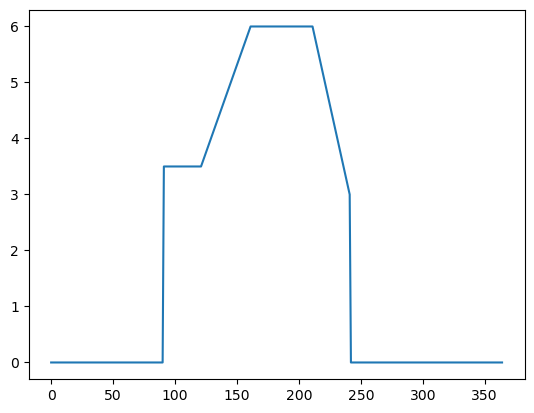

In [ ]:
plt.plot(cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0])

In [18]:
inv_K_y = np.where(cost_model._get_yield_coefficient(0,365)[0,:]==0, 0, cost_model._get_yield_coefficient(0,365)[0,:])

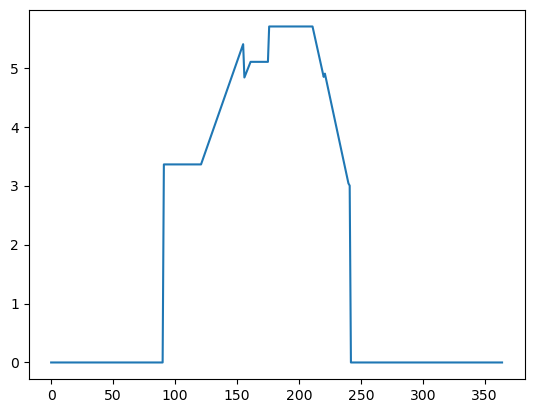

In [22]:
plt.plot((cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0])*(1-0.1*inv_K_y))

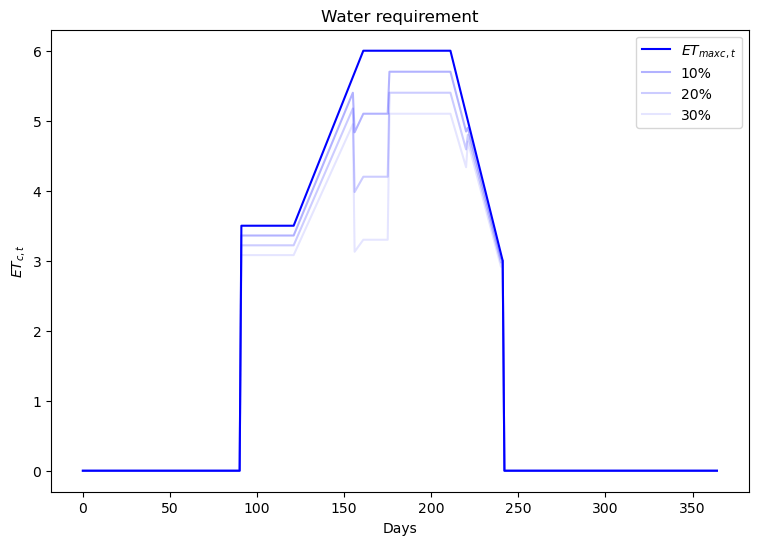

In [37]:
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(1, 1, 1)

ttl = f"Water requirement"
ax.set_title(ttl)
ax.set_xlabel("Days")
ax.set_ylabel("$ET_{c,t}$")

ax.plot(cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0], 'blue', label='${ET_{max}}_{c,t}$')
# ax.plot(cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0], 'blue')
plt.plot((cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0])*(1-0.1*inv_K_y), 'blue', alpha=0.3, label='10%')
plt.plot((cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0])*(1-0.2*inv_K_y), 'blue', alpha=0.2, label='20%')
plt.plot((cost_model._get_max_evapotranspiration(0,365)[0,0,:]/cost_model.land_surface_v[0])*(1-0.3*inv_K_y), 'blue', alpha=0.1, label='30%')
ax.legend()